In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Day 13: NumPy Data Filtering

## Objective
Use NumPy conditions and Boolean indexing to filter numerical values above, below, or equal to a specified threshold.

## Learning Goals
- Create a NumPy array of student marks.
- Apply Boolean conditions.
- Filter values using Boolean indexing.
- Compare marks against different thresholds.
- Visualize original data and filtered results using Matplotlib.

In [3]:
students = np.array([
    "S1", "S2", "S3", "S4", "S5",
    "S6", "S7", "S8", "S9", "S10"
])

marks = np.array([45, 67, 78, 52, 91, 83, 29, 76, 88, 60])

print("Student IDs:")
print(students)

print("\nOriginal Marks:")
print(marks)

print("\nTotal Students:", len(marks))

Student IDs:
['S1' 'S2' 'S3' 'S4' 'S5' 'S6' 'S7' 'S8' 'S9' 'S10']

Original Marks:
[45 67 78 52 91 83 29 76 88 60]

Total Students: 10


In [4]:
threshold = 50

condition = marks > threshold

print("Marks:", marks)
print("\nCondition (marks > 50):")
print(condition)

Marks: [45 67 78 52 91 83 29 76 88 60]

Condition (marks > 50):
[False  True  True  True  True  True False  True  True  True]


In [ ]:
above_50 = marks[marks > 50]
students_above_50 = students[marks > 50]

print("Marks greater than 50:")
print(above_50)

print("\nStudents scoring above 50:")
print(students_above_50)

Marks greater than 50:
[67 78 52 91 83 76 88 60]

Students scoring above 50:
['S2' 'S3' 'S4' 'S5' 'S6' 'S8' 'S9' 'S10']


In [6]:
below_50 = marks[marks < 50]
students_below_50 = students[marks < 50]

print("Marks below 50:")
print(below_50)

print("\nStudents scoring below 50:")
print(students_below_50)

Marks below 50:
[45 29]

Students scoring below 50:
['S1' 'S7']


In [7]:
equal_50 = marks[marks == 50]

print("Marks equal to 50:")
print(equal_50)

Marks equal to 50:
[]


In [8]:
thresholds = [40, 50, 70, 80]

for value in thresholds:
    filtered_marks = marks[marks > value]

    print(f"\nMarks greater than {value}:")
    print(filtered_marks)
    print("Count:", len(filtered_marks))


Marks greater than 40:
[45 67 78 52 91 83 76 88 60]
Count: 9

Marks greater than 50:
[67 78 52 91 83 76 88 60]
Count: 8

Marks greater than 70:
[78 91 83 76 88]
Count: 5

Marks greater than 80:
[91 83 88]
Count: 3


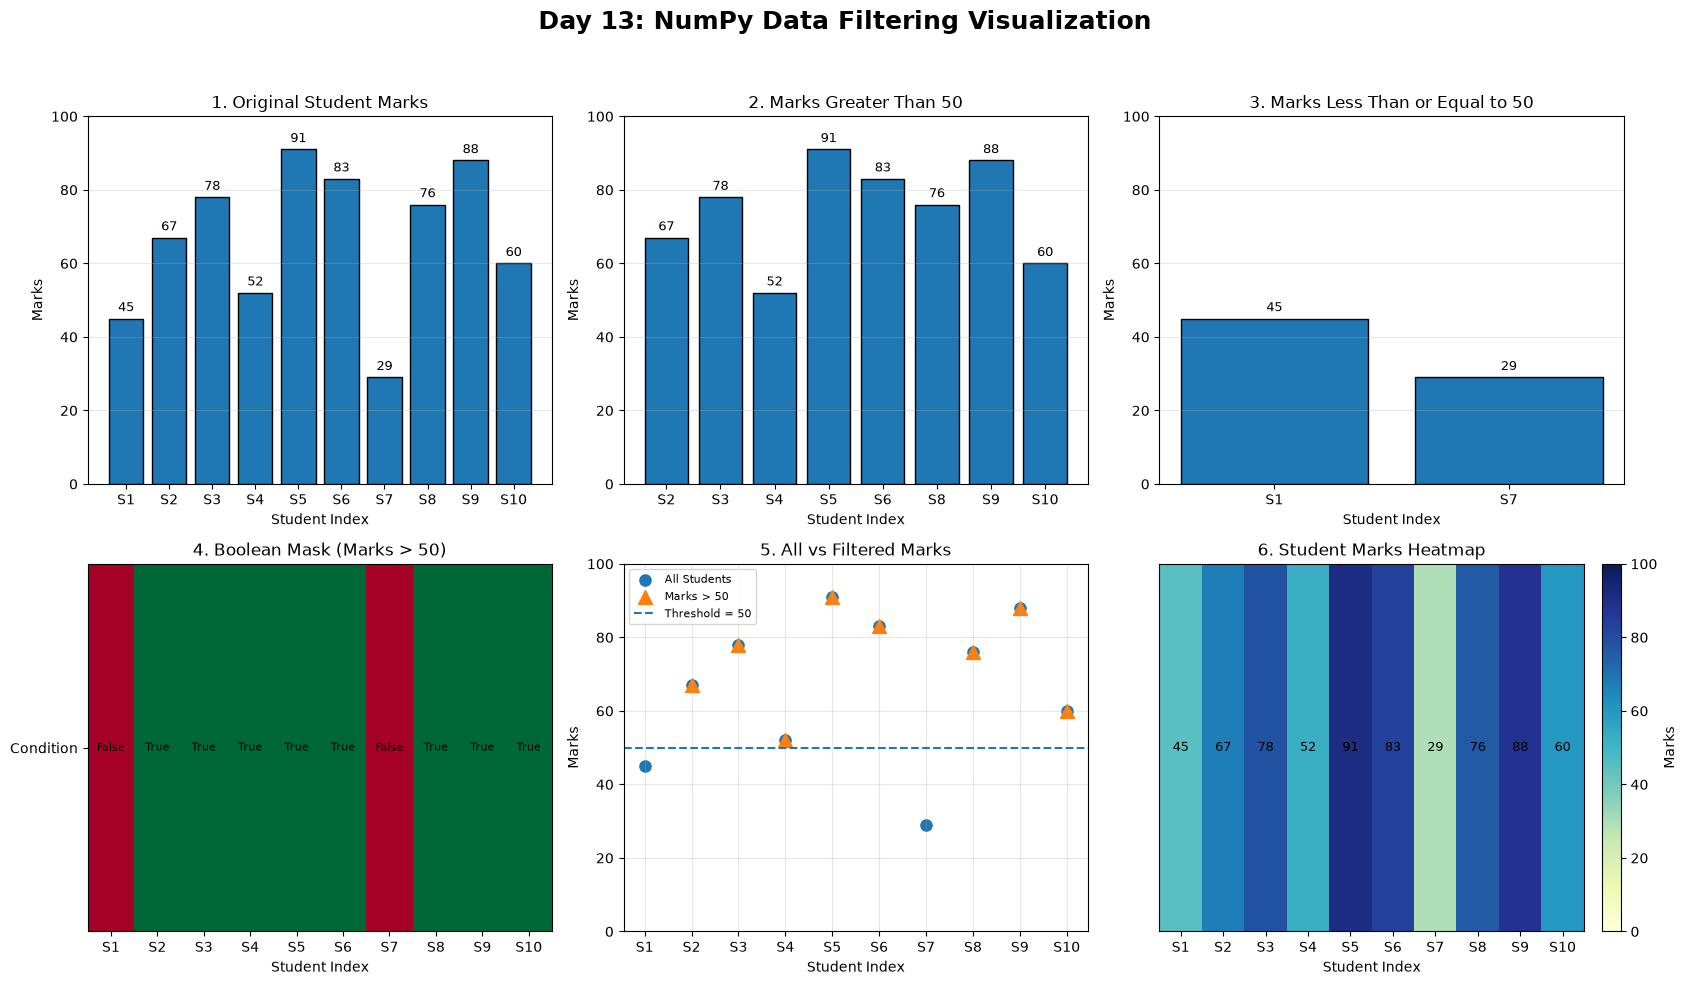

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

fig.suptitle(
    "Day 13: NumPy Data Filtering Visualization",
    fontsize=18,
    fontweight="bold"
)

# 1. Original student marks
axes[0, 0].bar(students, marks, edgecolor="black")
axes[0, 0].set_title("1. Original Student Marks")
axes[0, 0].set_xlabel("Student Index")
axes[0, 0].set_ylabel("Marks")
axes[0, 0].set_ylim(0, 100)
axes[0, 0].grid(axis="y", alpha=0.3)

for i, value in enumerate(marks):
    axes[0, 0].text(i, value + 2, str(value),
                    ha="center", fontsize=9)

# 2. Marks greater than 50
mask_above = marks > 50

axes[0, 1].bar(
    students[mask_above],
    marks[mask_above],
    edgecolor="black"
)
axes[0, 1].set_title("2. Marks Greater Than 50")
axes[0, 1].set_xlabel("Student Index")
axes[0, 1].set_ylabel("Marks")
axes[0, 1].set_ylim(0, 100)
axes[0, 1].grid(axis="y", alpha=0.3)

for i, value in enumerate(marks[mask_above]):
    axes[0, 1].text(i, value + 2, str(value),
                    ha="center", fontsize=9)

# 3. Marks less than or equal to 50
mask_below_equal = marks <= 50

axes[0, 2].bar(
    students[mask_below_equal],
    marks[mask_below_equal],
    edgecolor="black"
)
axes[0, 2].set_title("3. Marks Less Than or Equal to 50")
axes[0, 2].set_xlabel("Student Index")
axes[0, 2].set_ylabel("Marks")
axes[0, 2].set_ylim(0, 100)
axes[0, 2].grid(axis="y", alpha=0.3)

for i, value in enumerate(marks[mask_below_equal]):
    axes[0, 2].text(i, value + 2, str(value),
                    ha="center", fontsize=9)

# 4. Boolean mask visualization
mask = marks > 50

axes[1, 0].imshow(
    mask.reshape(1, -1),
    cmap="RdYlGn",
    aspect="auto",
    vmin=0,
    vmax=1
)
axes[1, 0].set_title("4. Boolean Mask (Marks > 50)")
axes[1, 0].set_xlabel("Student Index")
axes[1, 0].set_yticks([0])
axes[1, 0].set_yticklabels(["Condition"])
axes[1, 0].set_xticks(range(len(students)))
axes[1, 0].set_xticklabels(students)

for i, value in enumerate(mask):
    axes[1, 0].text(
        i, 0, "True" if value else "False",
        ha="center", va="center",
        fontsize=8,
        color="black"
    )

# 5. All marks vs filtered marks
axes[1, 1].scatter(
    students, marks,
    label="All Students",
    s=65
)
axes[1, 1].scatter(
    students[mask],
    marks[mask],
    label="Marks > 50",
    marker="^",
    s=100
)
axes[1, 1].axhline(
    y=50,
    linestyle="--",
    label="Threshold = 50"
)
axes[1, 1].set_title("5. All vs Filtered Marks")
axes[1, 1].set_xlabel("Student Index")
axes[1, 1].set_ylabel("Marks")
axes[1, 1].set_ylim(0, 100)
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(alpha=0.3)

# 6. Marks intensity heatmap
heatmap = axes[1, 2].imshow(
    marks.reshape(1, -1),
    cmap="YlGnBu",
    aspect="auto",
    vmin=0,
    vmax=100
)
axes[1, 2].set_title("6. Student Marks Heatmap")
axes[1, 2].set_xlabel("Student Index")
axes[1, 2].set_yticks([])
axes[1, 2].set_xticks(range(len(students)))
axes[1, 2].set_xticklabels(students)

for i, value in enumerate(marks):
    axes[1, 2].text(
        i, 0, str(value),
        ha="center", va="center",
        fontsize=9
    )

fig.colorbar(
    heatmap,
    ax=axes[1, 2],
    label="Marks",
    fraction=0.046,
    pad=0.04
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [10]:
print("=" * 40)
print("DAY 13: DATA FILTERING SUMMARY")
print("=" * 40)

print("Total students:", len(marks))
print("Threshold:", threshold)

print("\nMarks greater than 50:", above_50)
print("Count above 50:", len(above_50))

print("\nMarks below 50:", below_50)
print("Count below 50:", len(below_50))

print("\nMarks equal to 50:", equal_50)
print("Count equal to 50:", len(equal_50))

print("\nMarks less than or equal to 50:",
      marks[marks <= 50])

print("\nFiltering completed successfully!")

DAY 13: DATA FILTERING SUMMARY
Total students: 10
Threshold: 50

Marks greater than 50: [67 78 52 91 83 76 88 60]
Count above 50: 8

Marks below 50: [45 29]
Count below 50: 2

Marks equal to 50: []
Count equal to 50: 0

Marks less than or equal to 50: [45 29]

Filtering completed successfully!
